# Run the reproduction on Google Colab
First choose a GPU runtime: **Runtime > Change runtime type > T4 GPU**. Without it every script runs on the CPU and the training steps take many times longer.

## Before you start
This notebook reproduces every number and figure of the conference paper with seven scripts, run in order.
Each script saves its results on Google Drive as it goes, so if Colab disconnects, rerun the setup cells and then the
script that stopped: it continues where it left off.

**Needs:** a Colab GPU runtime (T4), about 12 GB of RAM, and a few GB of space on Drive for the dataset and caches.
The PhysioNet EEG Motor Movement/Imagery dataset is downloaded automatically by the first script.

### Setup: mount Google Drive and set the paths
`WORK` is the folder on Drive that holds the data (`data/`) and the results (`results/`).
`REPO` is the folder that holds these scripts. Change both paths if your folders have other names.

In [1]:
from google.colab import drive
drive.mount("/content/drive")
WORK = "/content/drive/MyDrive/transnn_mha_release"   # data/ and results/ go here
REPO = f"{WORK}/transnn-mha-leakage"                  # the code, on Drive (splits/ survives a disconnect)

Mounted at /content/drive


### Setup: install the libraries
Moves into the code folder and installs the packages in `requirements.txt`.
A red message from pip about dependency conflicts (for example `jedi` or `moviepy`) concerns Colab's own packages and can be ignored.

In [2]:
%cd "{REPO}"
!pip install -q -r requirements.txt

### Step 1: features (`01_features.py`), about 1 hour
Re-implements the authors' feature extraction. For each of the 14 runs of the 109 subjects, the whole 2-minute recording
is filtered (0.5–40 Hz), cleaned with ICA and reduced to 258 numbers (mean, variance, skewness and kurtosis of each
channel, plus alpha and beta power). This gives 1,526 real recordings in five classes.

**Check:** the last lines should read `total 1526` and `4905 samples (paper: 4,905)`, which is the authors' SMOTE count.
**Saves:** `data/features/S###.npz`, one file per subject.

In [ ]:
!python 01_features.py --data "{WORK}/data" --out "{WORK}/results"

S001 done |     1 s
S002 done |     1 s
S003 done |     1 s
S004 done |     1 s
S005 done |     1 s
S006 done |     1 s
S007 done |     1 s
S008 done |     1 s
S009 done |     1 s
S010 done |     1 s
S011 done |     1 s
S012 done |     1 s
S013 done |     1 s
S014 done |     1 s
S015 done |     1 s
S016 done |     1 s
S017 done |     1 s
S018 done |     1 s
S019 done |     1 s
S020 done |     1 s
S021 done |     1 s
S022 done |     1 s
S023 done |     1 s
S024 done |     1 s
S025 done |     1 s
S026 done |     1 s
S027 done |     1 s
S028 done |     1 s
S029 done |     1 s
S030 done |     1 s
S031 done |     1 s
S032 done |     1 s
S033 done |     1 s
S034 done |     1 s
S035 done |     1 s
S036 done |     1 s
S037 done |     1 s
S038 done |     1 s
S039 done |     1 s
S040 done |     1 s
S041 done |     1 s
S042 done |     1 s
S043 done |     1 s
S044 done |     1 s
S045 done |     1 s
S046 done |     1 s
S047 done |     1 s
S048 done |     1 s
S049 done |     1 s
S050 done |     1 s


### Step 2: the published pipeline, then one leak removed at a time (`02_protocols.py`), 1.5–2 hours
Trains TransNN-MHA, KNN and logistic regression under four protocols:
- **P0**: the authors' code. SMOTE and feature selection on all data before the 6-fold split; the test fold is also used for early stopping.
- **P1**: P0 with a separate validation set for early stopping.
- **P2**: SMOTE, scaling and feature selection inside each training fold; test folds hold real recordings only.
- **P3**: P2 with subject-wise folds, so every test fold contains new people.

**Check:** the summary at the end should read about P0 90%, P1 87%, P2 28% and P3 29% (Fig. 2 of the paper).
**Saves:** `results/protocols_summary.json`, and the folds and selected features in `splits/`, so later runs use the same splits.

In [ ]:
!python 02_protocols.py --data "{WORK}/data" --out "{WORK}/results"

I0000 00:00:1794917713.111223    1161 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Real recordings: 1526 [327, 327, 327, 327, 218] | after SMOTE on all data: 4905 (68.9% synthetic)
P0 fold 0 TransNN-MHA          accuracy 0.875 | macro-F1 0.875
P0 fold 0 KNN                  accuracy 0.759 | macro-F1 0.761
P0 fold 0 Logistic regression  accuracy 0.385 | macro-F1 0.375
P1 fold 0 TransNN-MHA          accuracy 0.872 | macro-F1 0.871
P0 fold 1 TransNN-MHA          accuracy 0.912 | macro-F1 0.912
P0 fold 1 KNN                  accuracy 0.786 | macro-F1 0.787
P0 fold 1 Logistic regression  accuracy 0.412 | macro-F1 0.402
P1 fold 1 TransNN-MHA          accuracy 0.844 | macro-F1 0.843
P0 fold 2 TransNN-MHA          accuracy 0.913 | macro-F1 0.913
P0 fold 2 KNN                  a

### Step 3: what the model learns (`03_diagnostics.py`), about 5 minutes
Pools the confusion matrices of P0 and P2 and computes precision, recall and F1 for each class. It then retrains fold 0
of P0 and P2 and keeps the training history, to draw the learning, ROC and precision–recall curves.

**Check:** P0 per-class scores near 0.9; P2 F1 between about 0.2 and 0.45; fold-0 ROC AUC about 0.97 for P0 and 0.64 for P2.
**Saves:** `results/confusion_pooled.json`, `results/per_class.csv`, `results/curves_fold0.json` (Figs. 3 and 4).

In [ ]:
!python 03_diagnostics.py --data "{WORK}/data" --out "{WORK}/results"

I0000 00:00:1794917962.443132    3567 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
protocol/model                class  precision  recall    f1
P0/TransNN-MHA  Imaginary Both Feet      0.880   0.874 0.877
P0/TransNN-MHA Imaginary Right Fist      0.895   0.884 0.889
P0/TransNN-MHA       Real Both Feet      0.905   0.890 0.897
P0/TransNN-MHA      Real Right Fist      0.883   0.900 0.891
P0/TransNN-MHA                 Rest      0.953   0.968 0.961
P1/TransNN-MHA  Imaginary Both Feet      0.827   0.853 0.840
P1/TransNN-MHA Imaginary Right Fist      0.838   0.855 0.847
P1/TransNN-MHA       Real Both Feet      0.872   0.842 0.857
P1/TransNN-MHA      Real Right Fist      0.853   0.823 0.838
P1/TransNN-MHA                 Rest      0.950   0.967 0.959
P2/TransNN-MHA  Imaginary 

### Step 4: leak-free reference decoders (`04_reference_decoders.py`), 3–4 hours
Evaluates two established decoders on subjects they have never seen (5 subject-wise folds, 106 subjects), using
cue-locked trials of 4 seconds and of 1 second:
- **CSP + LDA**: spatial filters with a linear classifier.
- **EEGNet**: a compact convolutional network, trained with three seeds (42, 7, 123) to measure training variability.

Three tasks: the paper's five classes, real vs imagined movement, and imagined left vs right fist.

**Check:** the last lines should read about 43% for five classes, 61% for real vs imagined and 77% for left vs right.
**Saves:** `data/trials/` (cached trials) and `results/reference_summary.json`.

In [ ]:
!python 04_reference_decoders.py --data "{WORK}/data" --out "{WORK}/results"

I0000 00:00:1794918143.292679    5764 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
S010 loaded |   239 s
S020 loaded |   470 s
S030 loaded |   703 s
S040 loaded |   936 s
S050 loaded |  1170 s
S060 loaded |  1401 s
S070 loaded |  1638 s
S080 loaded |  1869 s
S090 loaded |  2080 s
5class         1s CSP + LDA  seed None accuracy 0.214 +/- 0.005 |  2562 s
W0000 00:00:1794920713.517342    5764 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1794920713.519886    5764 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00

### Step 5: statistics (`05_statistics.py`), a few minutes, no GPU needed
Tests every result against chance (chance computed from each confusion matrix; permutation test with 10,000 shuffles;
t-test over folds; Holm correction), compares EEGNet with CSP + LDA fold by fold, and breaks EEGNet's five-class
accuracy into rest, limb and real-vs-imagined decisions.

**Check:** every leak-free result is above chance except CSP + LDA on real vs imagined; EEGNet beats CSP + LDA by about 22 points.
**Saves:** `results/stats_vs_chance.csv`, `results/stats_paired.csv`, `results/eegnet_breakdown.json`.

In [ ]:
!python 05_statistics.py --out "{WORK}/results"

         task               model setting  accuracy  chance  ci_folds_low  ci_folds_high  p_permutation_holm  p_fold_t_holm
       5class           CSP + LDA      1s    0.2138  0.2001        0.2075         0.2200              0.0028         0.0097
       5class           CSP + LDA      4s    0.2199  0.2002        0.2055         0.2343              0.0028         0.0368
       5class     EEGNet seed 123      4s    0.4295  0.2000        0.4109         0.4481              0.0028         0.0000
       5class      EEGNet seed 42      1s    0.3963  0.2000        0.3831         0.4098              0.0028         0.0000
       5class      EEGNet seed 42      4s    0.4427  0.2001        0.4356         0.4498              0.0028         0.0000
       5class       EEGNet seed 7      4s    0.4312  0.1999        0.4210         0.4416              0.0028         0.0000
       5class                 KNN      P0    0.7592  0.2000        0.7430         0.7754              0.0028         0.0000
       5

### Step 6: figures (`06_figures.py`), seconds
Draws Figs. 1–5 of the paper from the saved results and shows them below.
**Saves:** `results/figures/` (PNG at 600 dpi and PDF).

Fig. 2 saved
Fig. 3 saved
Fig. 4 saved
Fig. 5 saved


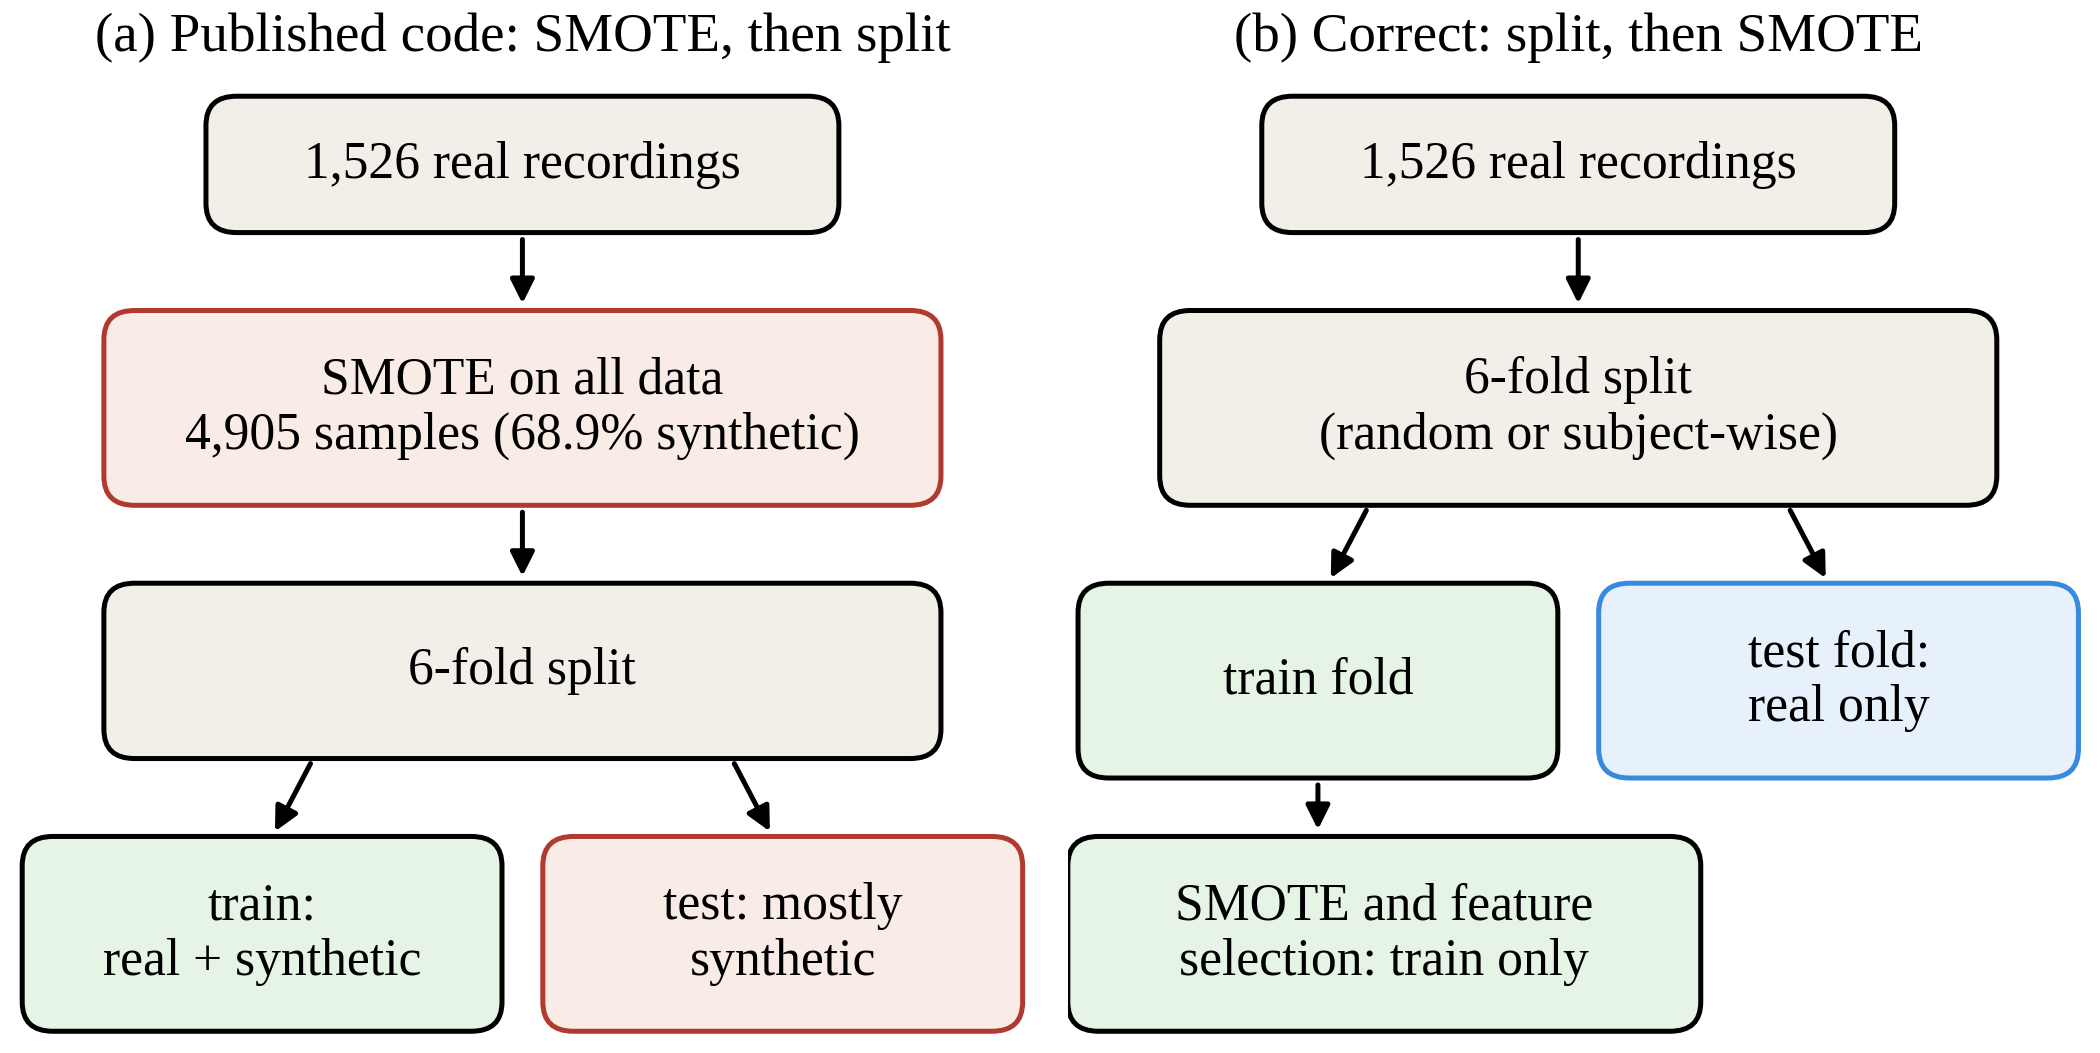

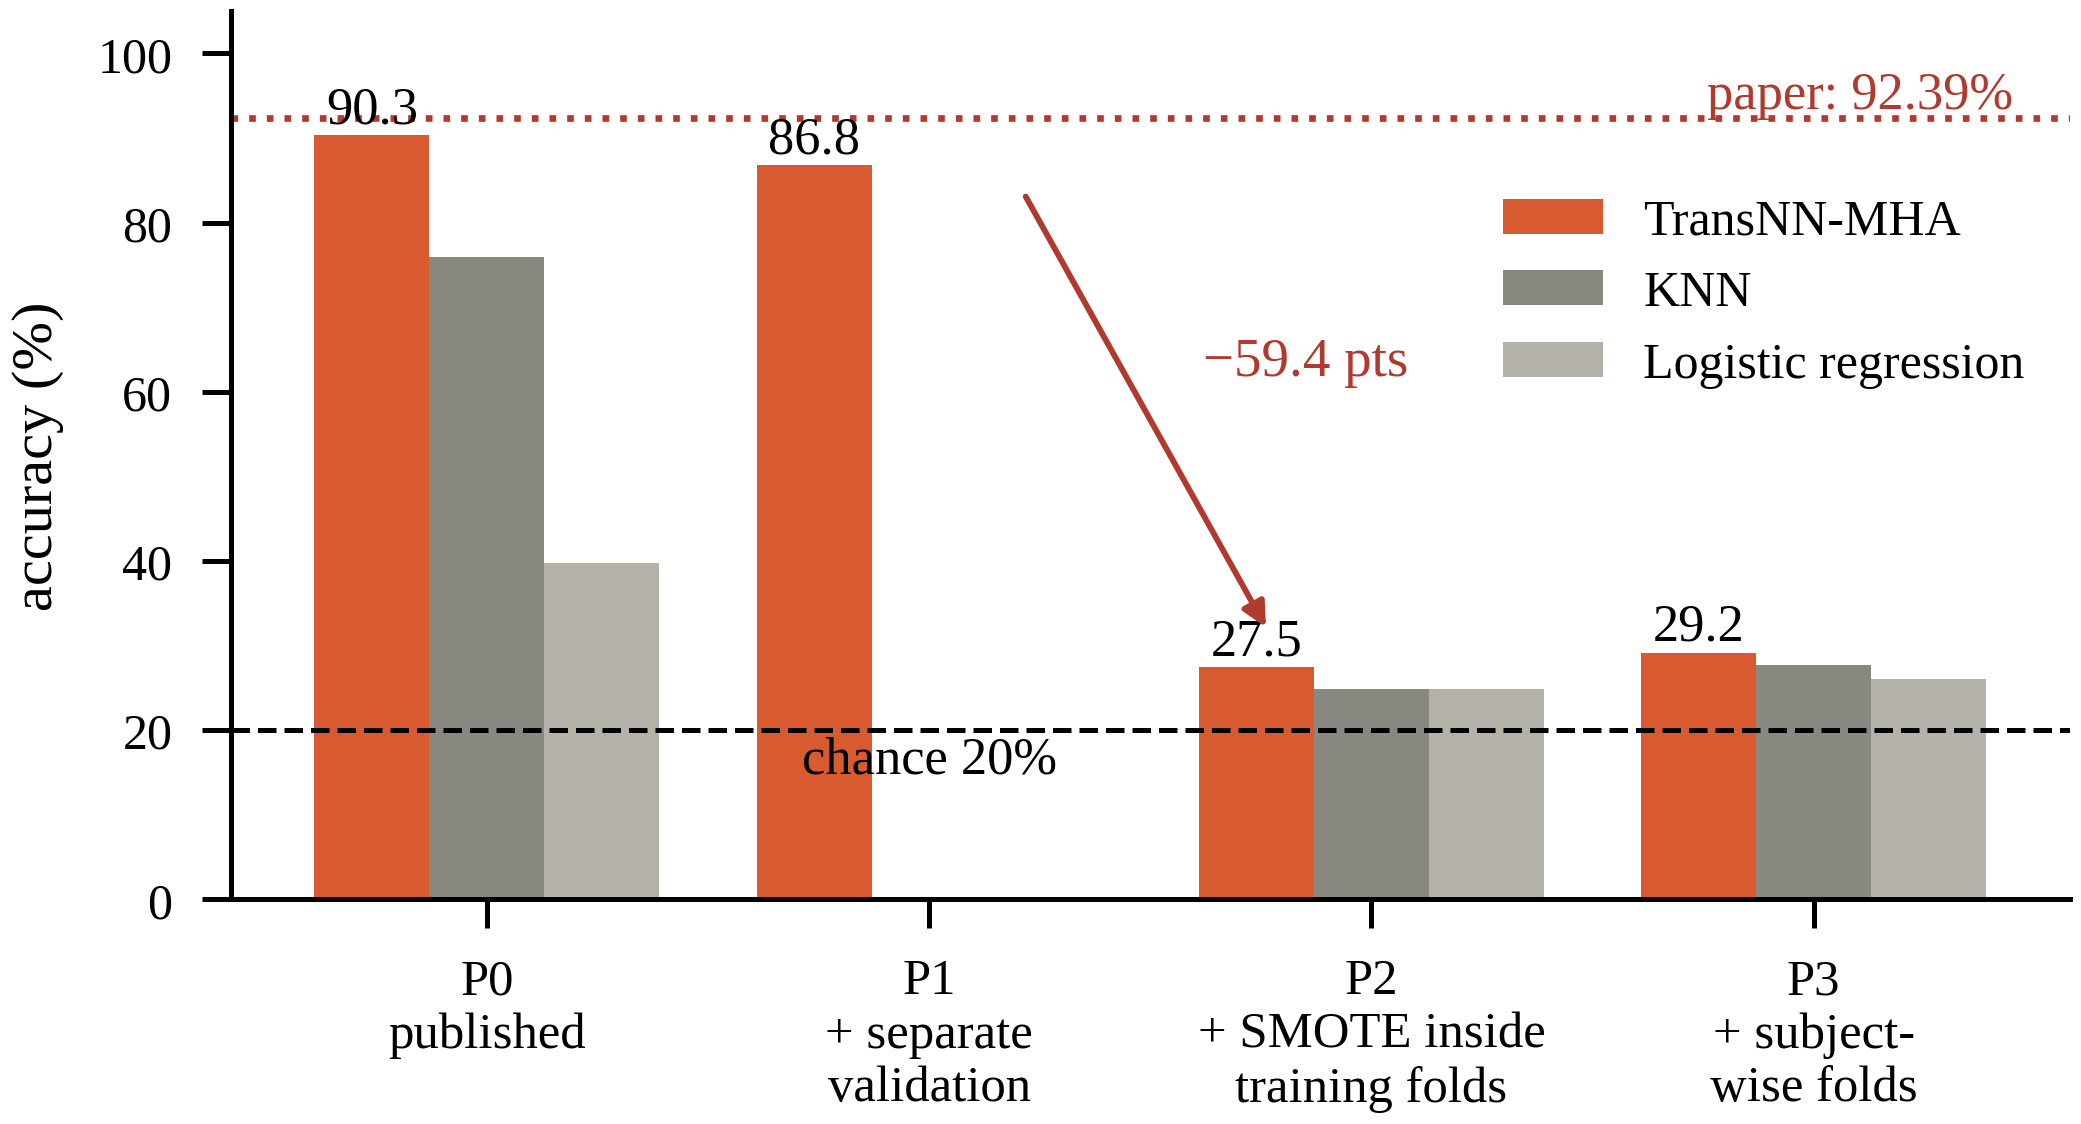

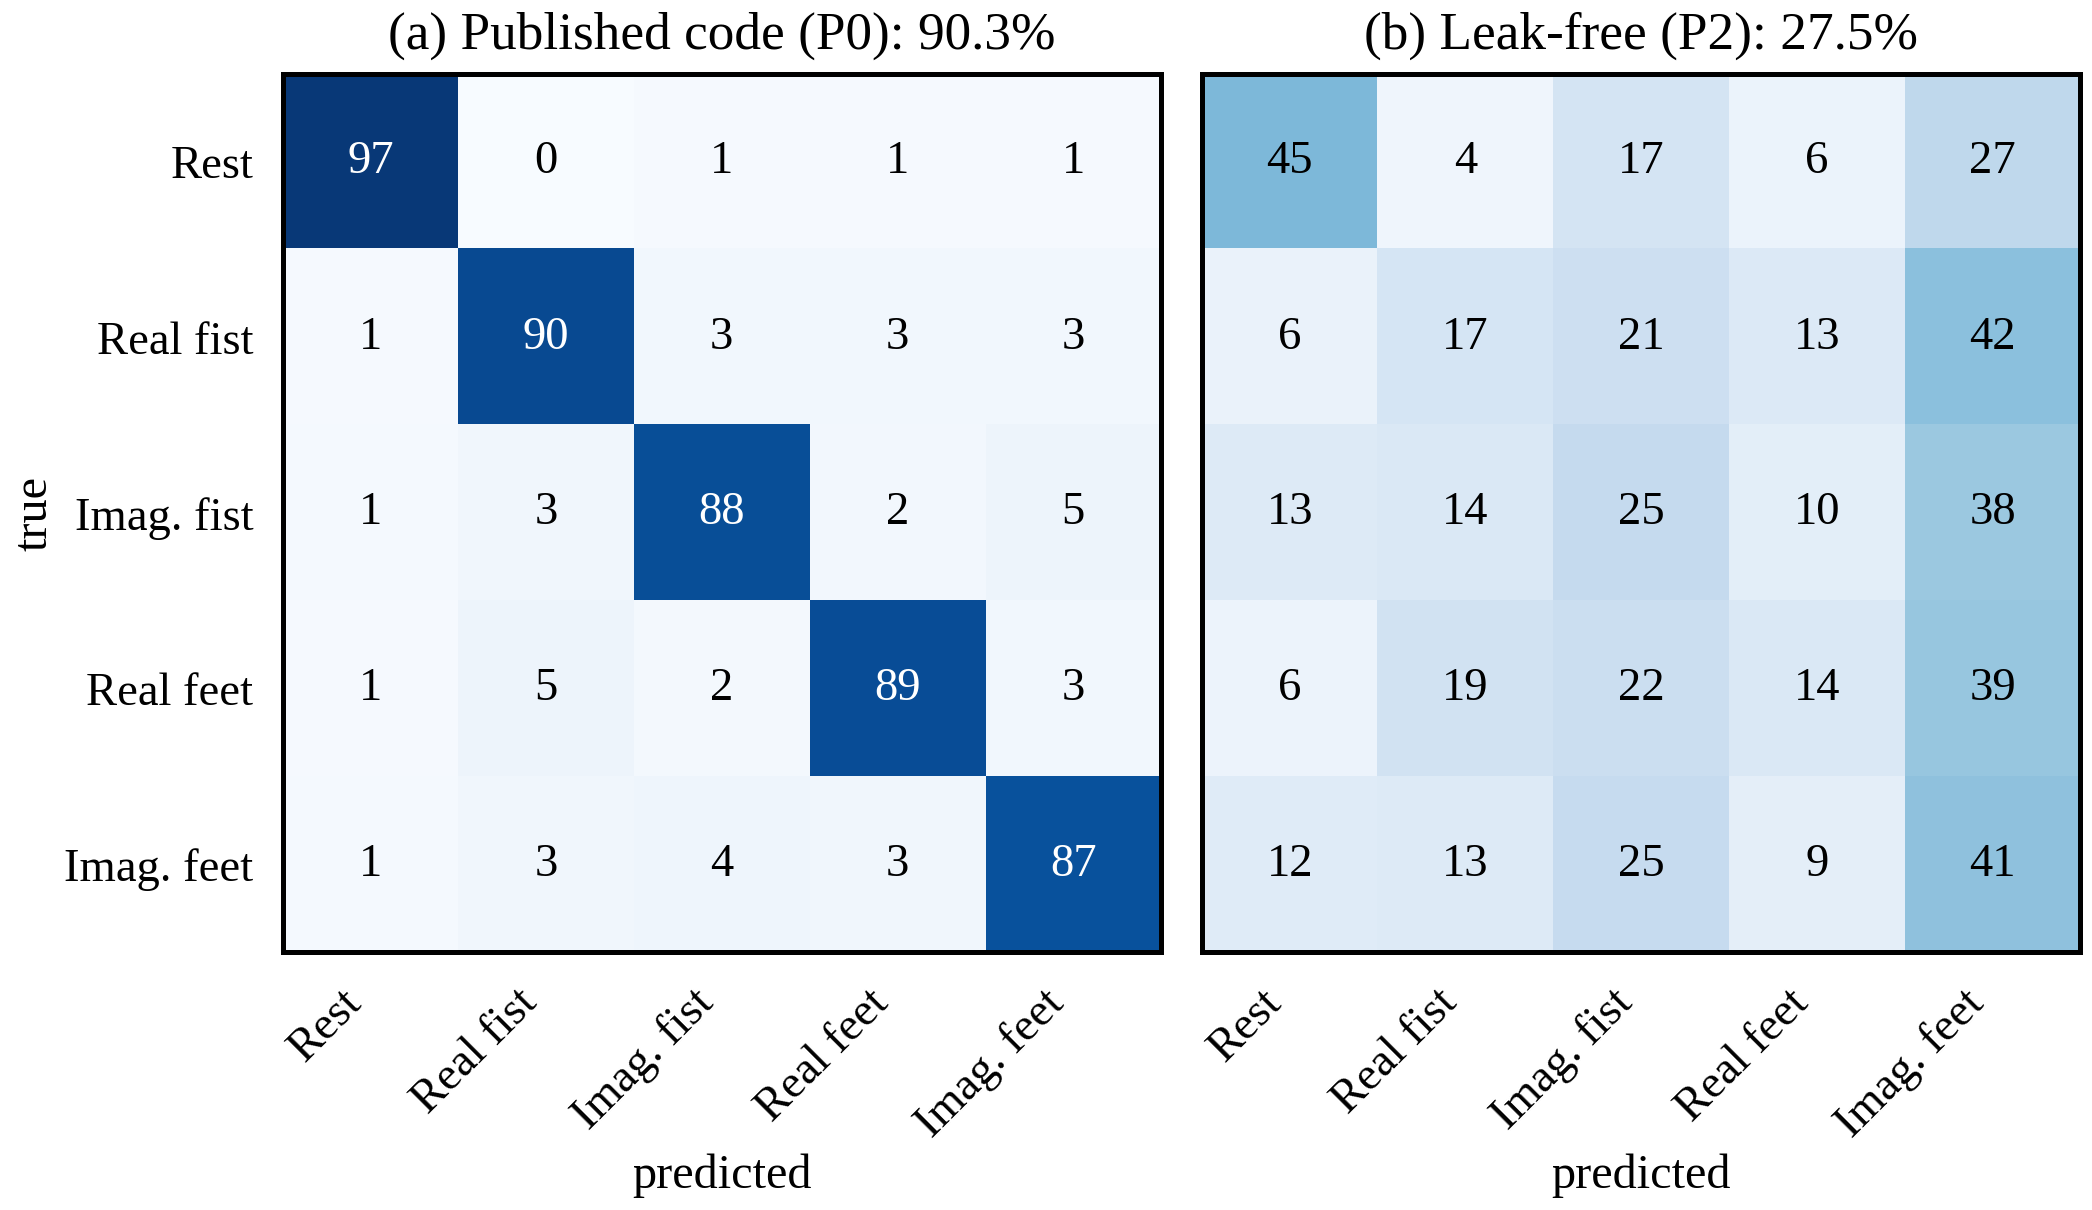

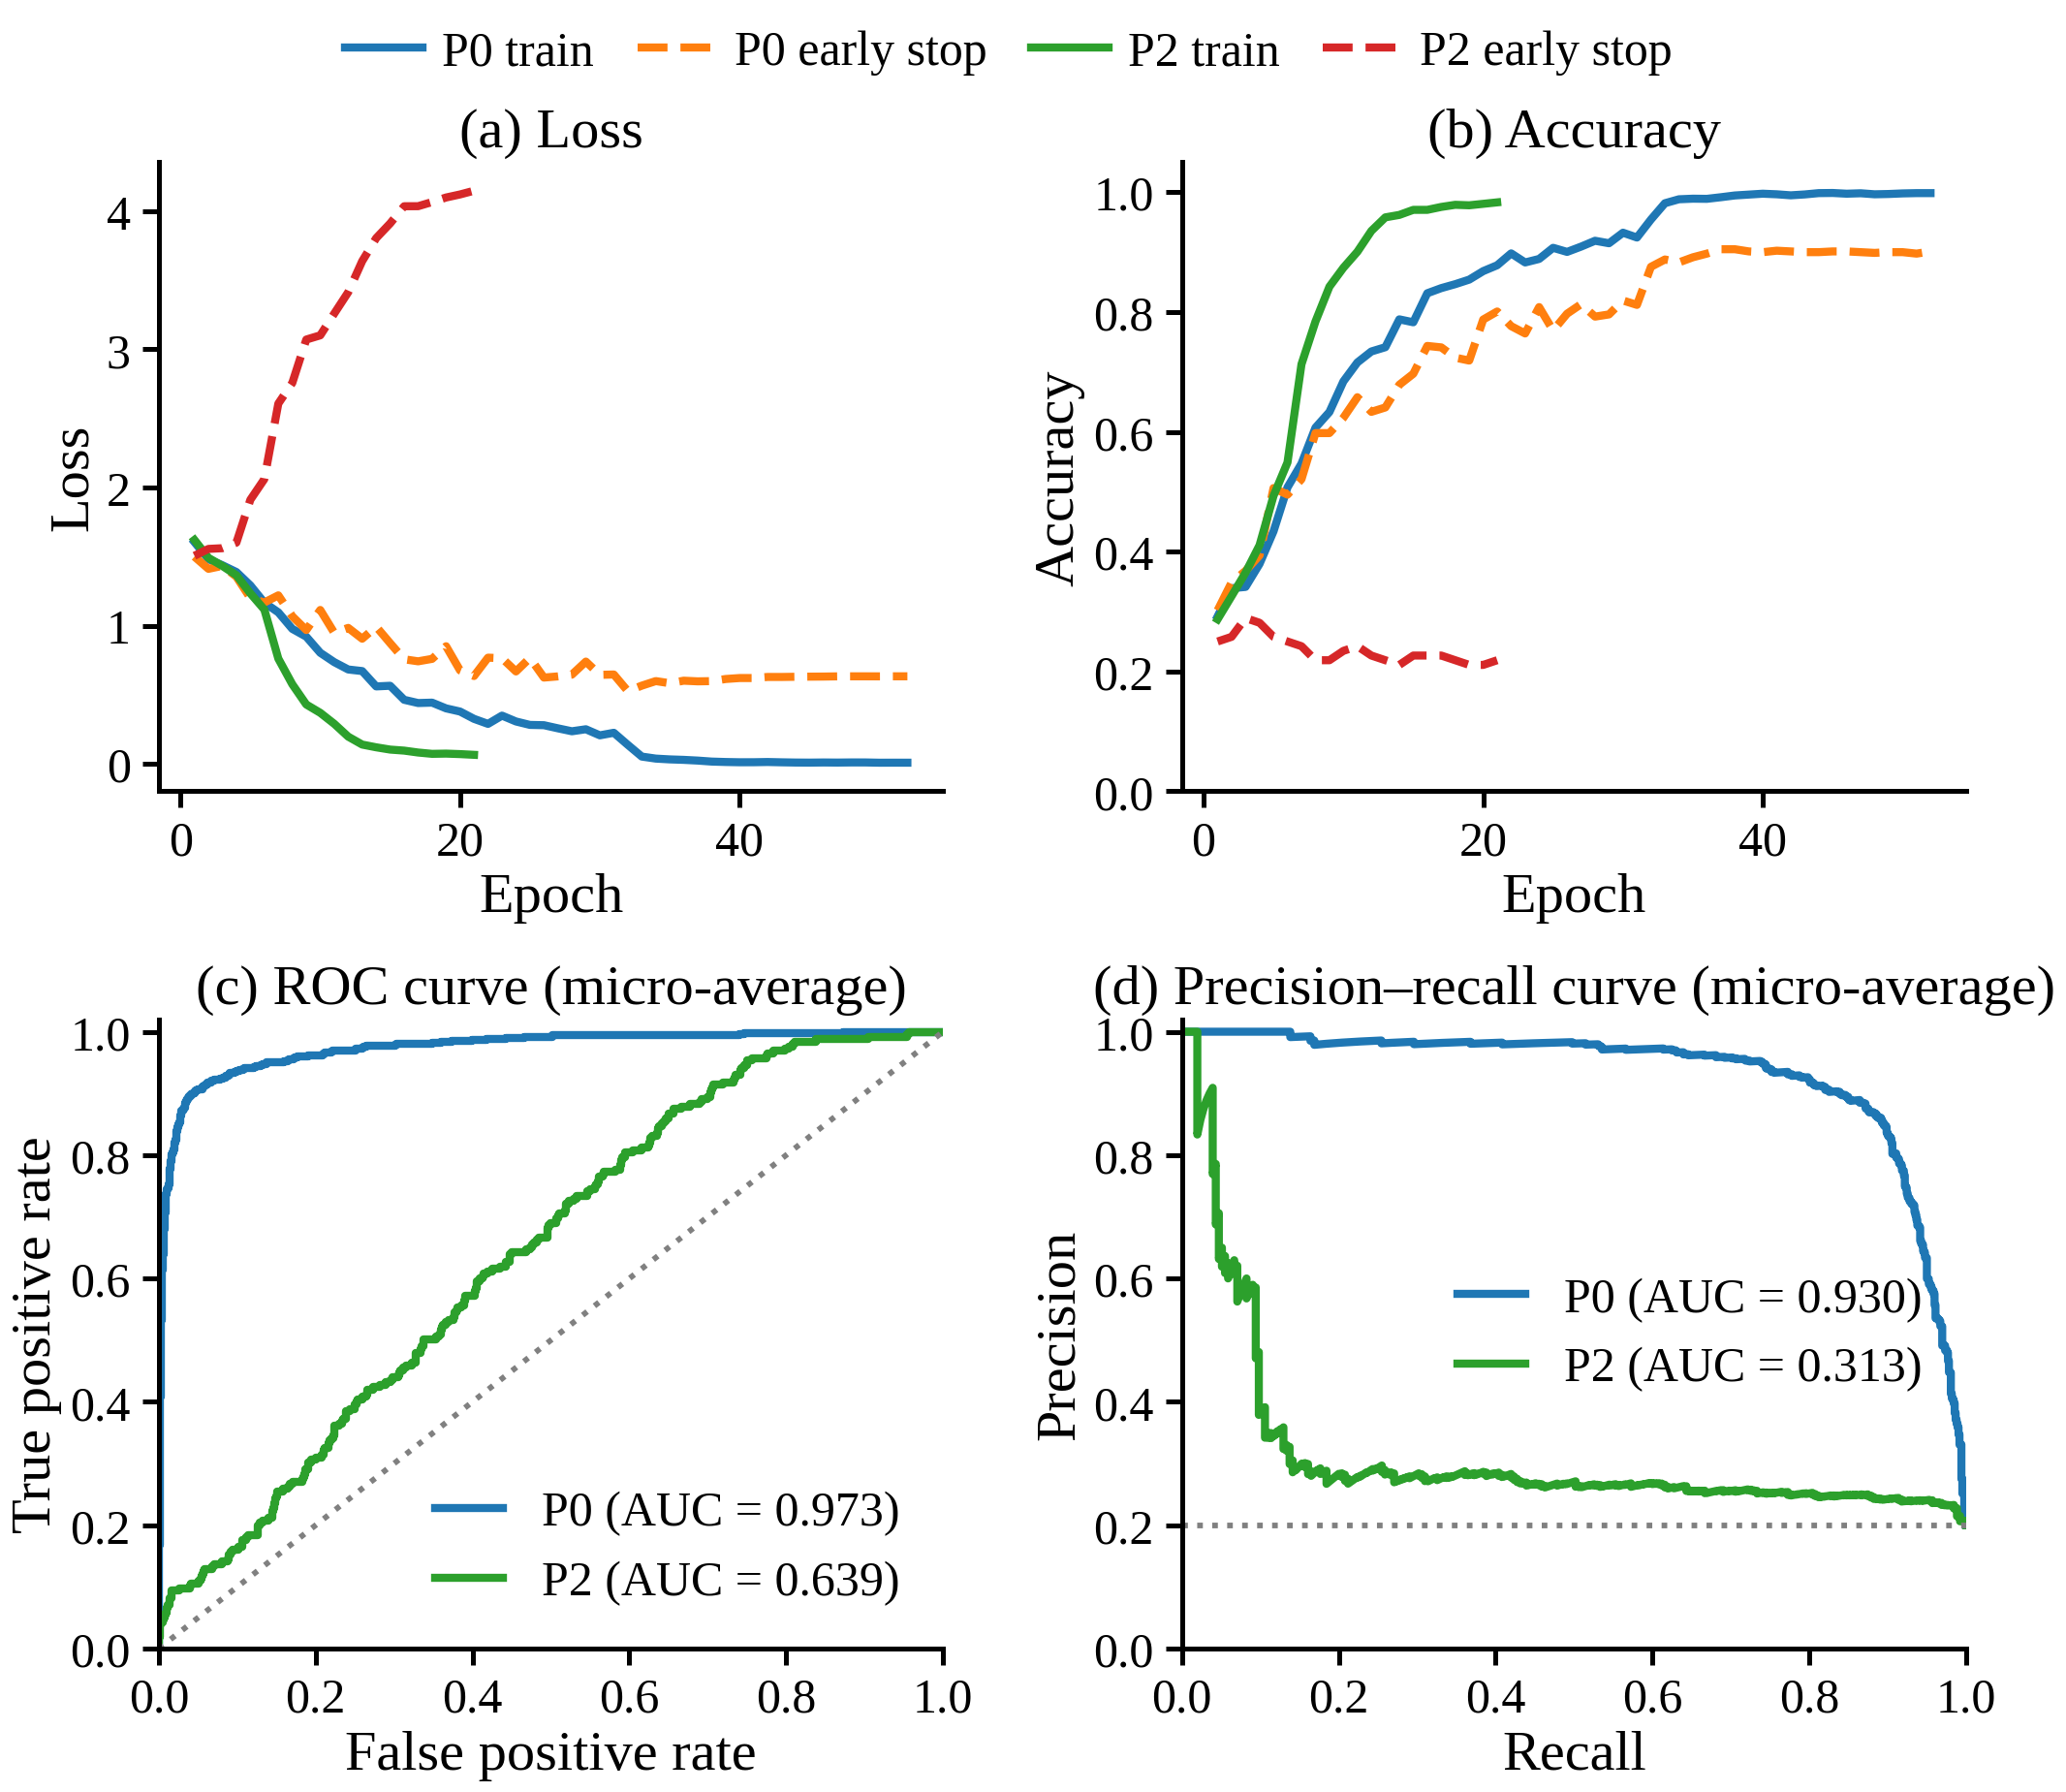

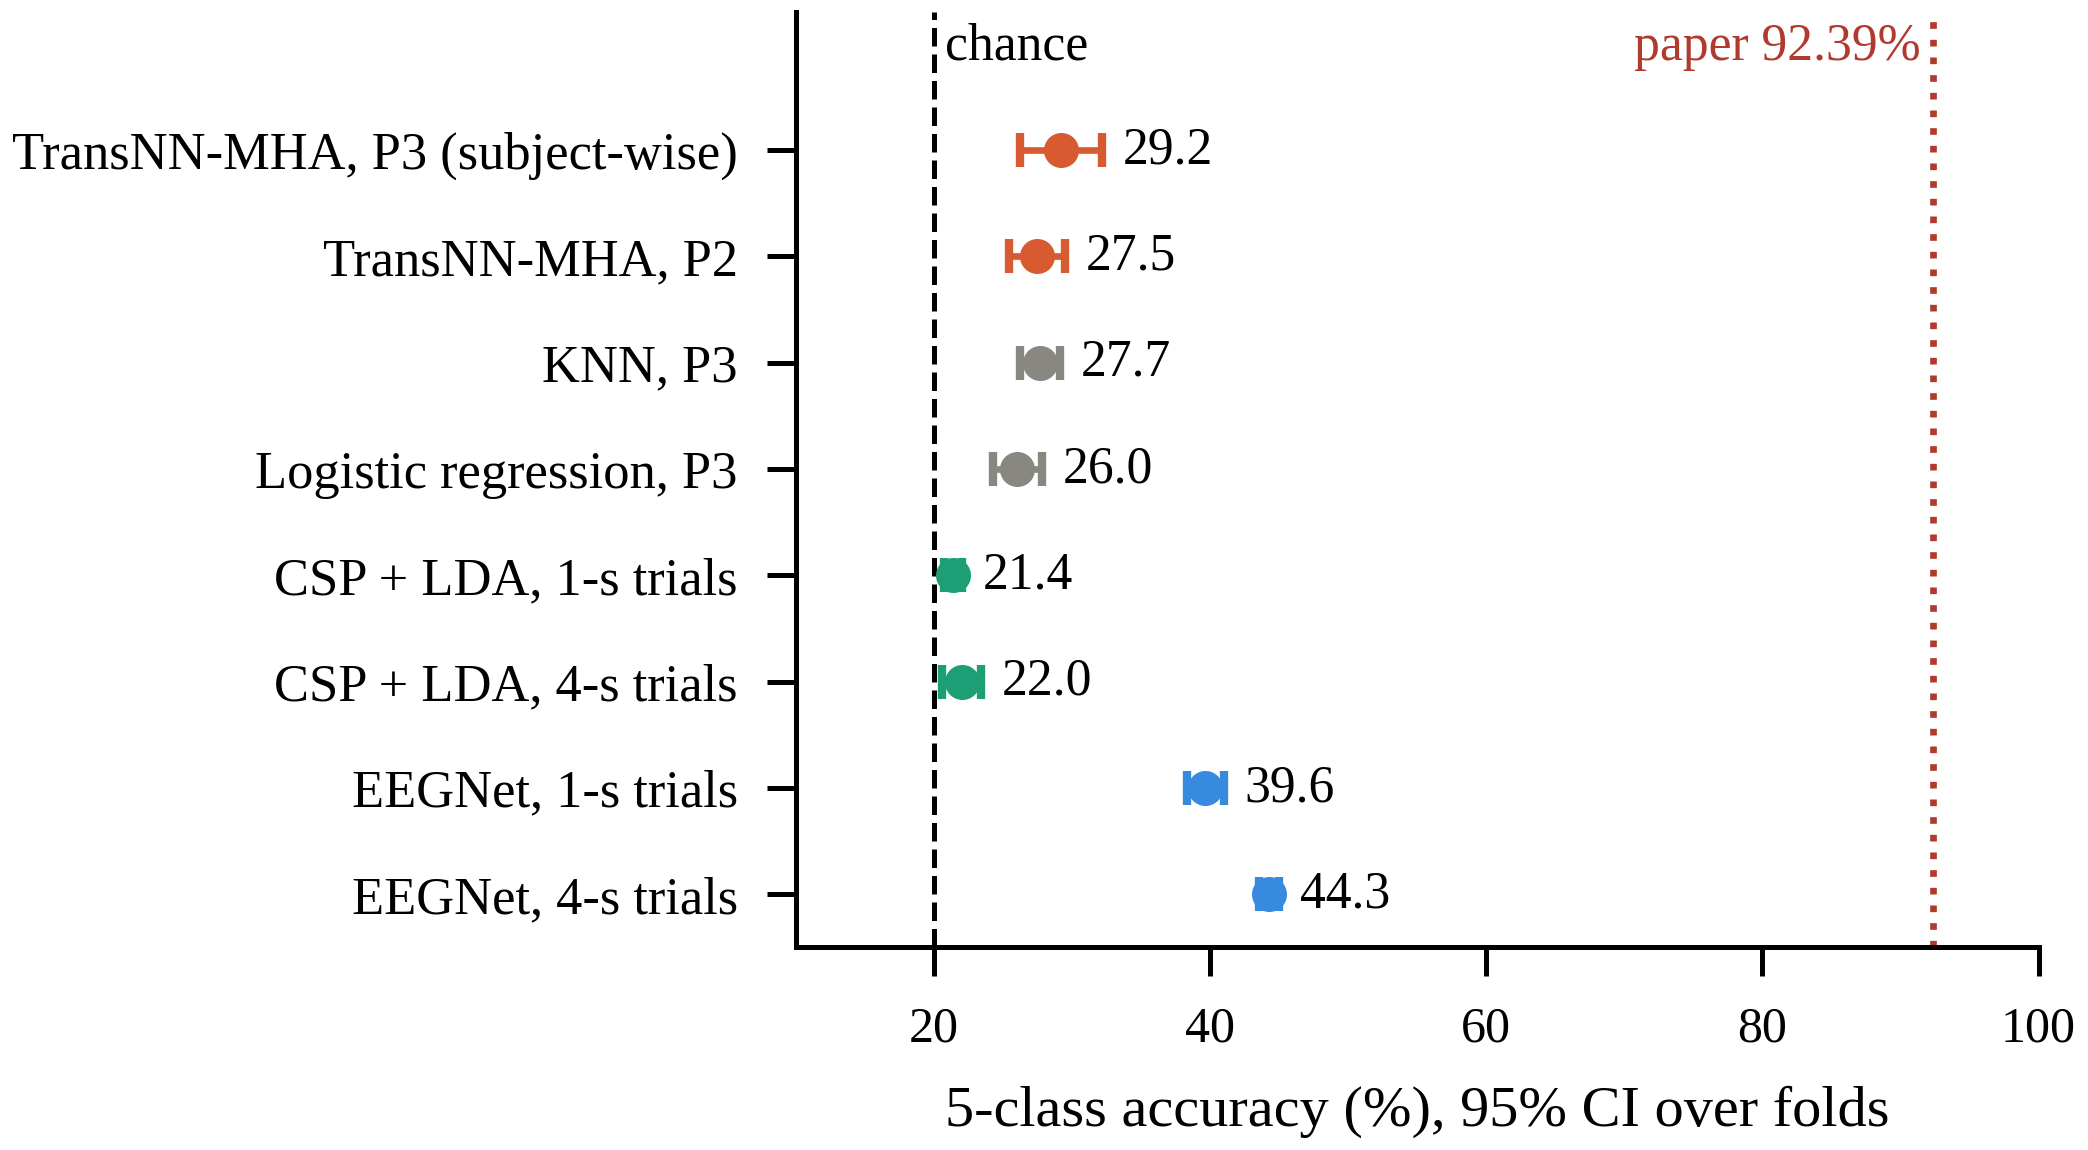

In [ ]:
!python 06_figures.py --out "{WORK}/results"
from IPython.display import Image, display
import glob
for f in sorted(glob.glob(f"{WORK}/results/figures/*.png")):
    display(Image(f, width=520))

### Step 7 (optional): does the oversampling choice matter? (`07_augmentation_ablation.py`)
Repeats P2 and P3 with only the training data changed: the authors' SMOTE, SMOTE only to balance the classes, no
oversampling, class weights, and random crops of the real training runs (augmentation with real signal instead of
synthetic samples). Test folds are unchanged. This checks the Section IV-B statement that the leak-free result does not
depend on the oversampling choice. Needs Steps 1 and 2.

**Time:** building the crop features is the slow part, roughly 3–10 minutes per subject (about 10 hours in total, so expect at least one Colab disconnect); training then takes about an hour. Both parts resume after a disconnect.
**Check:** all conditions should give about 27–31% with paired p > 0.25.
**Saves:** `data/crops/`, `results/augmentation_summary.json`, `results/augmentation_paired.csv`.

In [3]:
!python 07_augmentation_ablation.py --data "{WORK}/data" --out "{WORK}/results"

I0000 00:00:1795019171.232605    1574 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795019171.299865    1574 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795019175.097840    1574 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
S001 crops ready |     1 s
S002 crops ready |     2 s
S003 crops ready |     3 s
S004 crops ready |     4 s
S005 crops ready |     4 s
S006 crops ready |     5 s
S007 crops ready |     6 s
S008 crops ready |     7 s
S009 crops ready |     7 s
S010 crops ready |     8 s
S011 crops ready |     9 s
S012 crops ready |    10 s
S013 crops ready |    10 s
S014 crops ready |    11 s
S015 crops ready |    12 s
S016 crops ready |    13 s
S017 crops ready |    14 

In [4]:
!pip freeze | grep -iE "tensorflow|keras|mne|scikit|imbalanced|numpy|scipy|pandas|matplotlib"

geopandas==1.2.0
imbalanced-learn==0.14.2
keras==3.13.2
keras-hub==0.26.0
keras-nlp==0.26.0
matplotlib==3.10.0
matplotlib-inline==0.2.2
matplotlib-venn==1.1.2
mne==1.13.2
numpy==2.4.6
pandas==2.2.3
pandas-datareader==0.11.1
pandas-gbq==0.30.0
pandas-stubs==2.2.3.250527
scikit-image==0.25.2
scikit-learn==1.6.1
scipy==1.16.3
sklearn-pandas==2.2.0
tensorflow==2.21.0
tensorflow-datasets==4.9.10
tensorflow-hub==0.16.1
tensorflow-metadata==1.21.0
tensorflow-probability==0.25.0
tensorflow-text==2.21.1
tf_keras==2.21.0
